In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from sklearn.preprocessing import StandardScaler

In [2]:
# Ideas
# 1 - explore psi/kwh relationship and psi/billing relationship for each well and aggregated wells

# 2 - logistic regression - how likely is a well to receive a workover based on its pressure reading?
#                         - what wells have A) abnormal billing costs, B) abnormal average pressures, C) abnormal maintenance needs

# 3 - linear regression - psi/kwh, psi/billing, kwh/maintenance, kwh/workover, billing/maintenance, billing/workover

# 4 - compare total_$/barrel to revenue/barrel

# 5 - For predictions/explanations - duplicate and normalize data columns, so that
#     one data column is used for display and another for prediction/explanation.

# Target metrics - Cost per barrels disposed for each well****
#               - kwh/barrel for each well 
#               - $/kwh for each well and field wide
#               - kwh/barrel * $/kwh = electrical_cost/barrel
#               1) electrical_cost/barrel + maintenance_cost/barrel + workover_cost/barrel = total_cost/barrel
#               2) revenue/barrel
#               3) income/barrel = revenue/barrel - total_cost/barrel


In [3]:
main_df = pd.read_excel(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\All Data.xlsx")
os.chdir(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis")
print(main_df.columns)

Index(['Unnamed: 0', 'Name', 'Year-Month', 'Hours', 'Water Total', 'PSI',
       'Revenue', 'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH',
       'Fuel Rate', 'Electrical Bill', 'Workover Info', 'Workover Cost',
       'Pump Model', 'Pump Number', 'Plunger Size', 'Install Date',
       'Maintenance Cost', 'Maintenance Comments'],
      dtype='object')


In [20]:
# Variable creation
# numpy.where(condition, true_result, false_result)

# prevent div by 0
# If no barrels were disposed, but we were still charged for the month
# record that to be used in estimates - still important for understanding efficiency of a site
# NOTE: WE WILL HAVE TO AVERAGE KWH PER BARREL BY THE PROPORTION OF WATER DISPOSED, NOT AS A BLIND AVERAGE
main_df["KWH per Barrel"] = np.where(
    main_df["Water Total"] > 0,
    main_df["Billing KWH"] / main_df["Water Total"],
    main_df["Billing KWH"]
)

# prevent div by 0
main_df["Cost per KWH"] = np.where(
    main_df["Billing KWH"] > 0,
    main_df["Electrical Bill"] / main_df["Billing KWH"],
    main_df["Electrical Bill"]
)

# prevent badly skewed values
# 8/10/2026 NOTE: Doesn't appear to be helping much.
# Will be better to just compare Electrical Cost to Water Total
main_df["Electrical Cost per Barrel"] = np.where(
    main_df["Water Total"] > 1000,
    main_df["KWH per Barrel"] * main_df["Cost per KWH"],
    main_df["Electrical Bill"]
)

main_df["Maintenance Cost per Barrel"] = np.where(
    main_df["Water Total"] > 0,
    main_df["Maintenance Cost"] / main_df["Water Total"],
    main_df["Maintenance Cost"]
)

main_df["Workover Cost per Barrel"] = np.where(
    main_df["Water Total"] > 0,
    main_df["Workover Cost"] / main_df["Water Total"],
    main_df["Workover Cost"]
)
# prevent div by 0
# Not sure why we would have revenue for no disposal totals, but just in case.
main_df["Revenue per Barrel"] = np.where(
    main_df["Water Total"] > 0,
    main_df["Revenue"] / main_df["Water Total"],
    main_df["Revenue"]
)

main_df["Income per Barrel"] = (
    main_df["Revenue per Barrel"] 
    - main_df["Electrical Cost per Barrel"] 
    - main_df["Maintenance Cost per Barrel"] 
    - main_df["Workover Cost per Barrel"]
)

main_df["Income"] = (
    main_df["Revenue"]
    - main_df["Electrical Bill"]
    - main_df["Maintenance Cost"]
    - main_df["Workover Cost"]
)

main_df["Total Cost"] = (
    main_df["Electrical Bill"]
    + main_df["Maintenance Cost"]
    + main_df["Workover Cost"]
)



main_df["6 Month Avg KWH"] = (
    main_df
    .groupby("Name")["Billing KWH"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Revenue"] = (
    main_df
    .groupby("Name")["Revenue"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Income"] = (
    main_df
    .groupby("Name")["Income"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Total Cost"] = (
    main_df
    .groupby("Name")["Total Cost"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Electrical Cost"] = (
    main_df
    .groupby("Name")["Electrical Bill"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Maintenance Cost"] = (
    main_df
    .groupby("Name")["Maintenance Cost"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Workover Cost"] = (
    main_df
    .groupby("Name")["Workover Cost"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)
main_df["6 Month Avg KWH per Barrel Weighted"] = (
    main_df
    .groupby("Name")["KWH per Barrel"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Cost per KWH"] = (
    main_df
    .groupby("Name")["Cost per KWH"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Electrical Cost per Barrel"] = (
    main_df
    .groupby("Name")["Electrical Cost per Barrel"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Maintenance Cost per Barrel"] = (
    main_df
    .groupby("Name")["Maintenance Cost per Barrel"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Workover Cost per Barrel"] = (
    main_df
    .groupby("Name")["Workover Cost per Barrel"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Revenue per Barrel"] = (
    main_df
    .groupby("Name")["Revenue per Barrel"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

main_df["6 Month Avg Income per Barrel"] = (
    main_df
    .groupby("Name")["Income per Barrel"]
    .rolling(window=6)
    .mean()
    .reset_index(drop=True)
)

# running totals for electrical, workover and maintenance costs
main_df["Cumulative Electrical Cost"] = main_df.groupby("Name")["Electrical Bill"].cumsum()
main_df["Cumulative Workover Cost"] = main_df.groupby("Name")["Workover Cost"].cumsum()
main_df["Cumulative Maintenance Cost"] = main_df.groupby("Name")["Maintenance Cost"].cumsum()
main_df["Cumulative Total Cost"] = main_df.groupby("Name")["Total Cost"].cumsum()

# running totals for income and revenue
main_df["Cumulative Income"] = main_df.groupby("Name")["Income"].cumsum()
main_df["Cumulative Revenue"] = main_df.groupby("Name")["Revenue"].cumsum()
wells = main_df["Name"].unique()
print(main_df.columns)

main_df.to_excel("Derived All Data.xlsx")

Index(['Unnamed: 0', 'Name', 'Year-Month', 'Hours', 'Water Total', 'PSI',
       'Revenue', 'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH',
       'Fuel Rate', 'Electrical Bill', 'Workover Info', 'Workover Cost',
       'Pump Model', 'Pump Number', 'Plunger Size', 'Install Date',
       'Maintenance Cost', 'Maintenance Comments', 'KWH per Barrel',
       'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       '6 Month Avg Water Total', '6 Month Avg KWH', '6 Month Avg Revenue',
       '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Ele

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


C:\Users\jroland\AppData\Local\Temp\ipykernel_3300\1211519486.py:19: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax1 = plt.subplots()


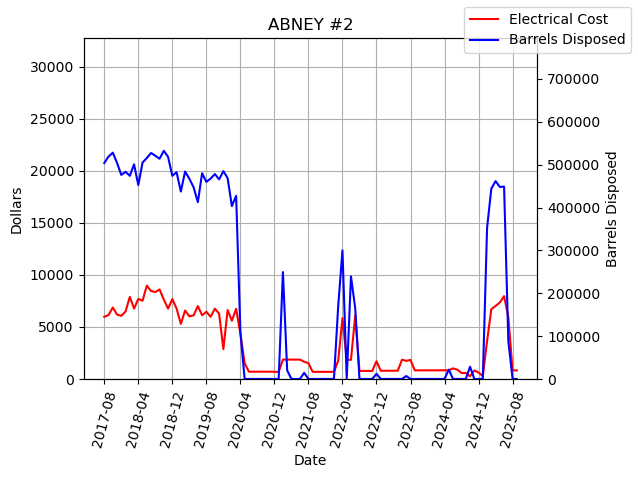

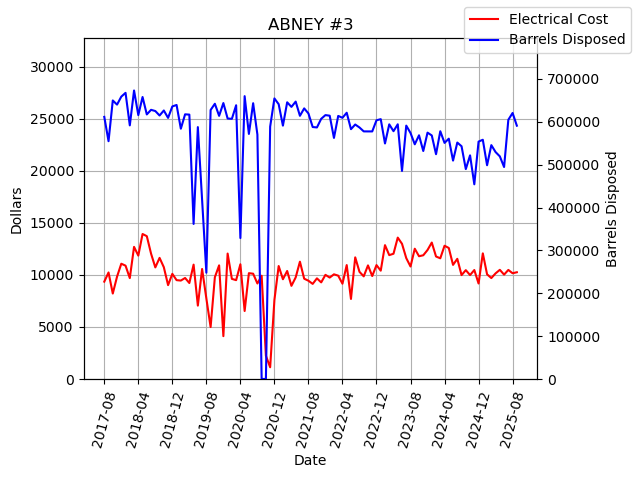

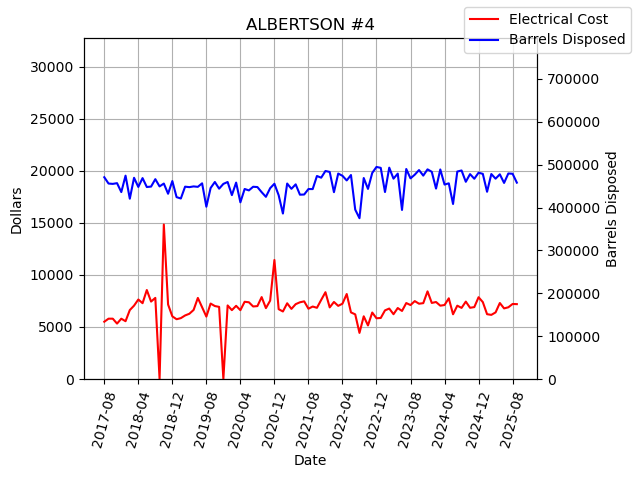

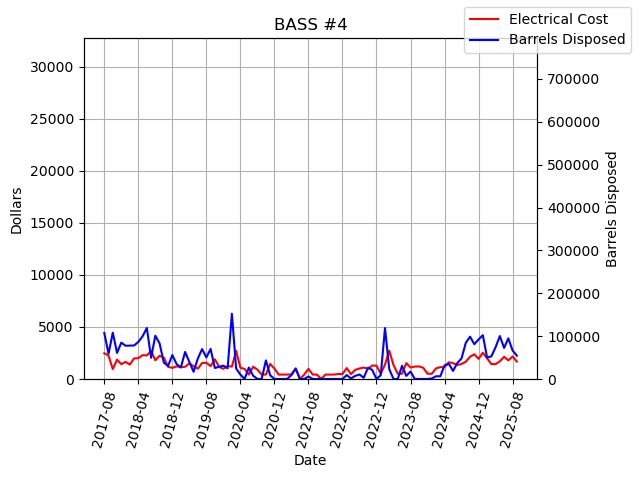

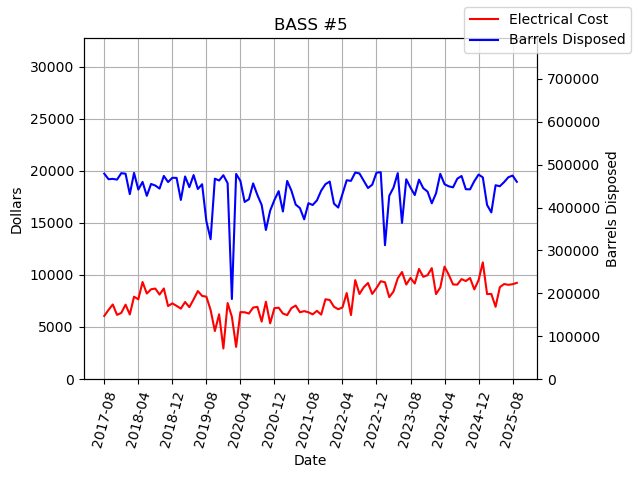

...

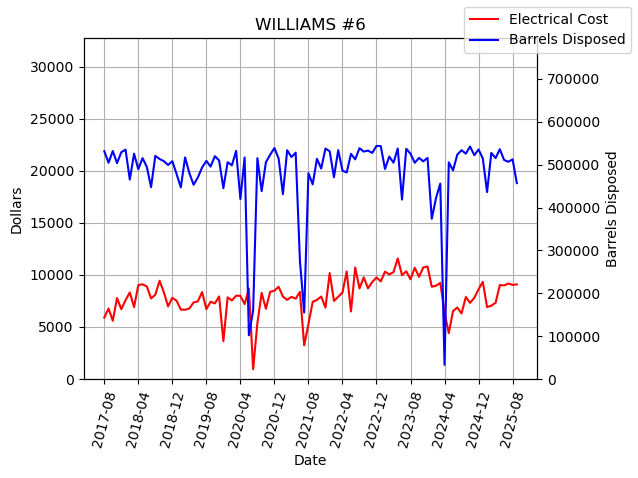

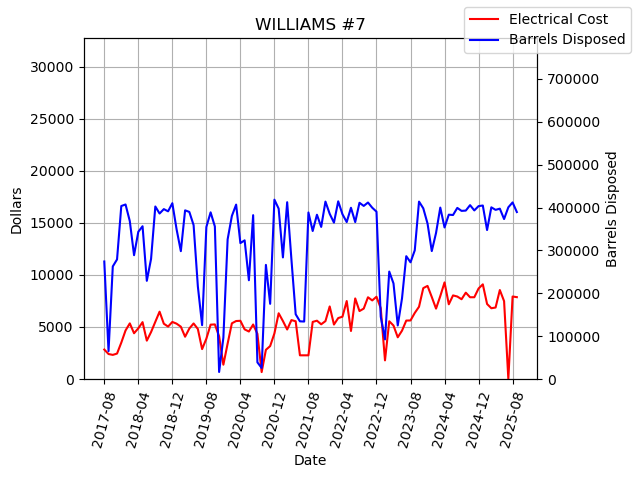

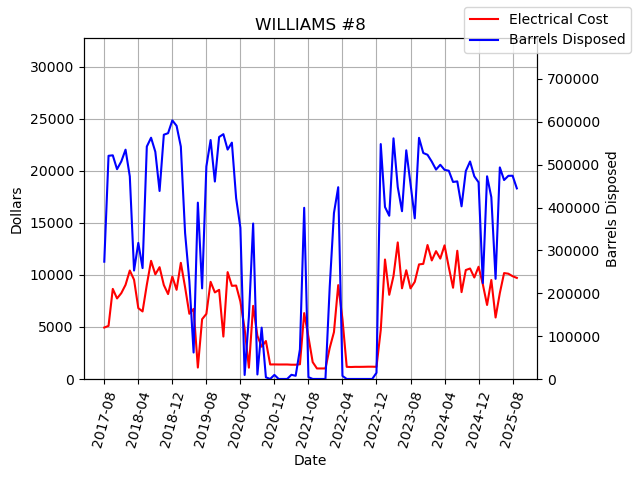

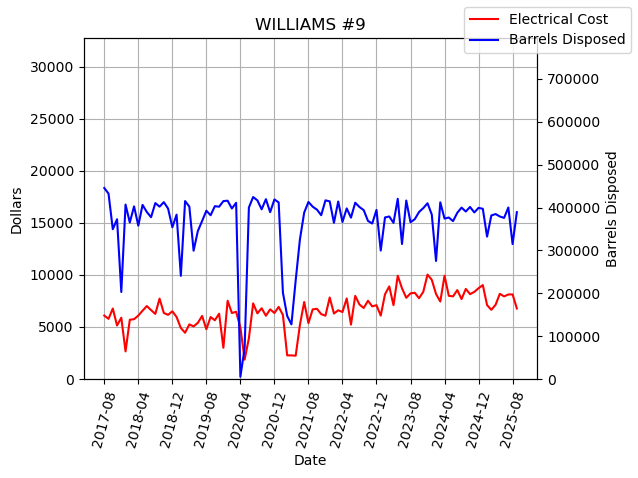

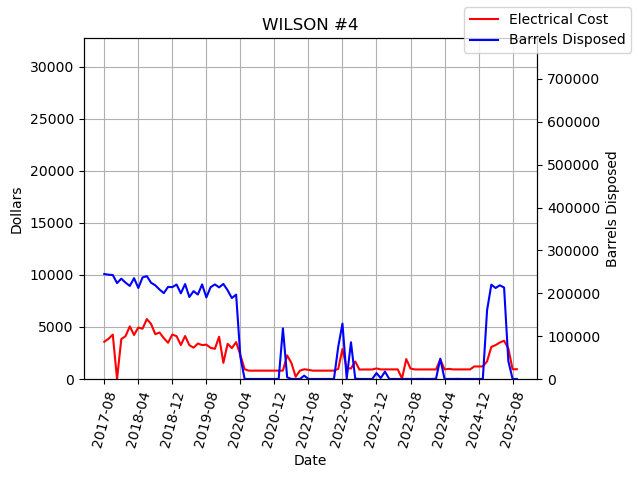

In [5]:
# Two sets of plots
# Plot one is a time series of each well
# - Plot Electrical Cost per Barrel 
#       Loop through each well, create a plot, output to pdf

# - Plot Revenue per Barrel
# - Plot Income per Barrel
#    - Each one of these can have plots for moving averages included
os.chdir(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Graphs")
print(plt.style.available)
plt.style.use("default")
# turn off figures displaying in notebook
plt.ioff()

# Electrical Bills vs Barrels
for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    fig, ax1 = plt.subplots()
    ax1.plot(
        filtered_df["Year-Month"], 
        filtered_df["Electrical Bill"], 
        label="Electrical Cost",
        color="red"
    )
    # creates a parallel y-axis
    ax2 = ax1.twinx()
    ax2.plot(
        filtered_df["Year-Month"], 
        filtered_df["Water Total"], 
        label="Barrels Disposed",
        color="blue"
    )
    # display legend for both axes
    fig.legend()
    ax1.grid()
    ax1.set_title(well)
    ax1.set_ylim(0, max(main_df["Electrical Bill"]))
    ax2.set_ylim(0, max(main_df["Water Total"]))
    ax1.tick_params(axis="x", rotation=75)
    # reduce number of x ticks
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.set_ylabel("Dollars")
    ax1.set_xlabel("Date")
    ax2.set_ylabel("Barrels Disposed")
    # adjust to prevent labels clipping on pdf
    plt.tight_layout()
    fig.savefig(well + "_electrical_vs_barrels.pdf")    


# Plot two are the values for all wells, time agnostic
# - Plot total income per barrel for each well - output to spreadsheet
# - Plot total income for each well - output to spreadsheet
# - Plot average income per barrel for each well (take the total and divide by barrels rather than averaging total income per barrel) - output to ss
# - Plot average income for each well - output to spreadsheet

In [5]:
print(main_df.columns)

Index(['Unnamed: 0', 'Name', 'Year-Month', 'Hours', 'Water Total', 'PSI',
       'Revenue', 'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH',
       'Fuel Rate', 'Electrical Bill', 'Workover Info', 'Workover Cost',
       'Pump Model', 'Pump Number', 'Plunger Size', 'Install Date',
       'Maintenance Cost', 'Maintenance Comments', 'KWH per Barrel',
       'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       '6 Month Avg Water Total', '6 Month Avg KWH', '6 Month Avg Revenue',
       '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Ele

C:\Users\jroland\AppData\Local\Temp\ipykernel_57224\3863617203.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax1 = plt.subplots()


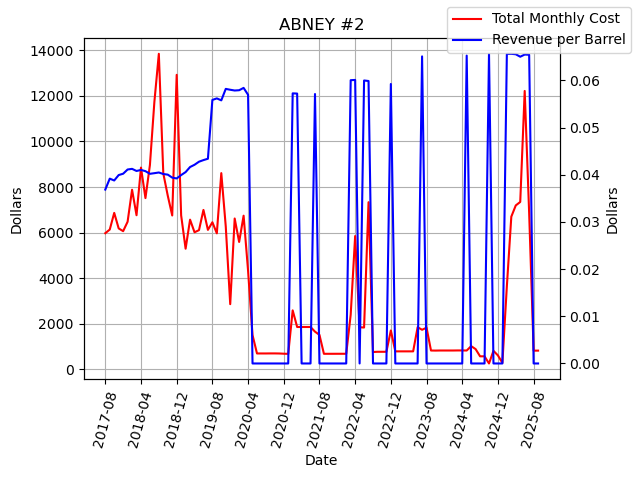

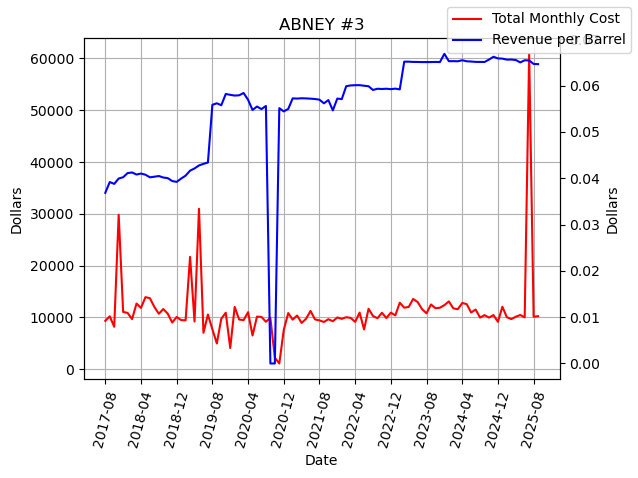

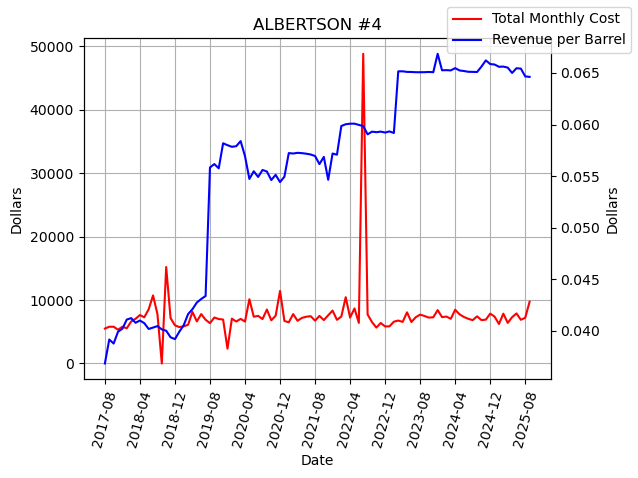

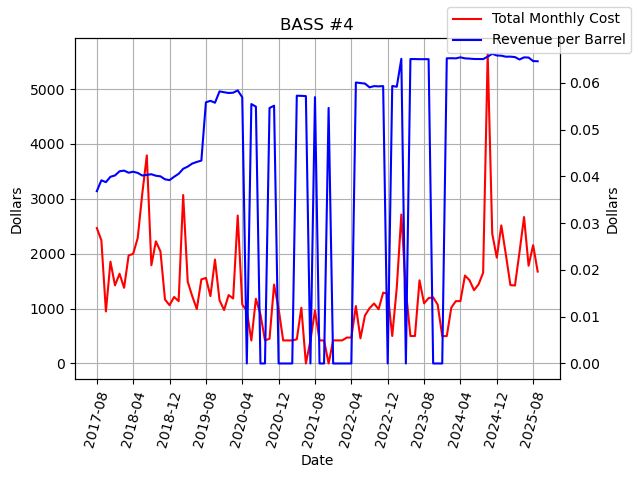

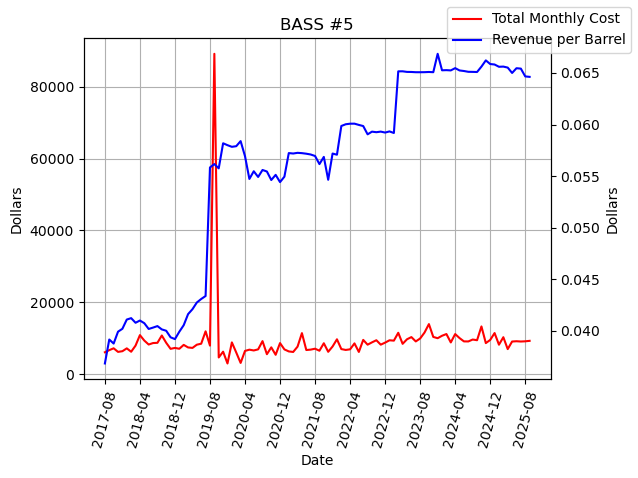

...

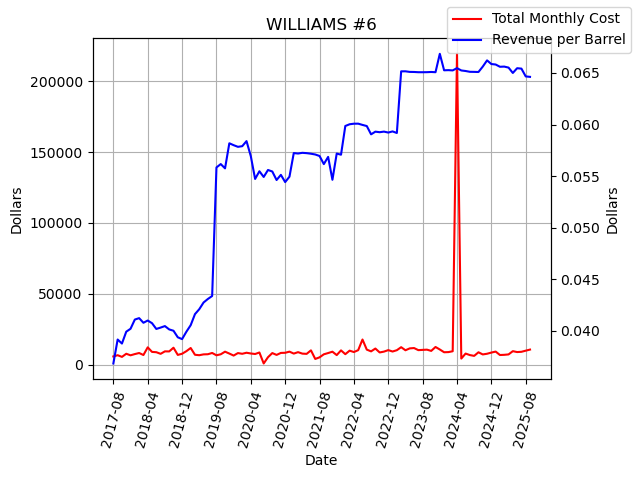

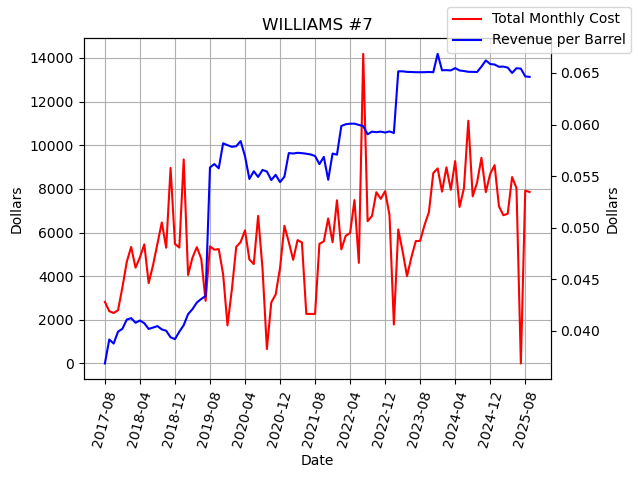

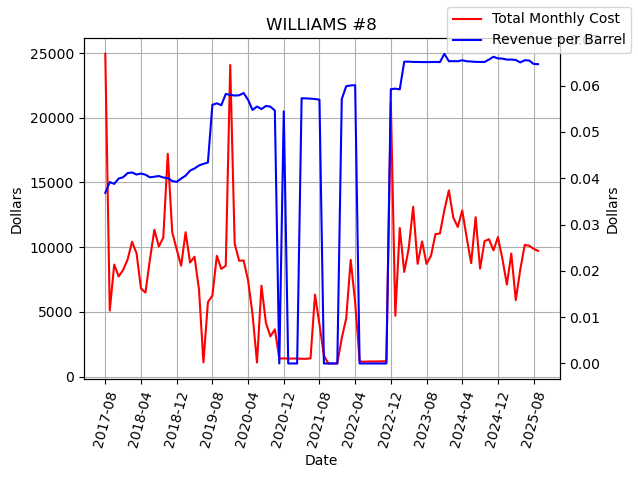

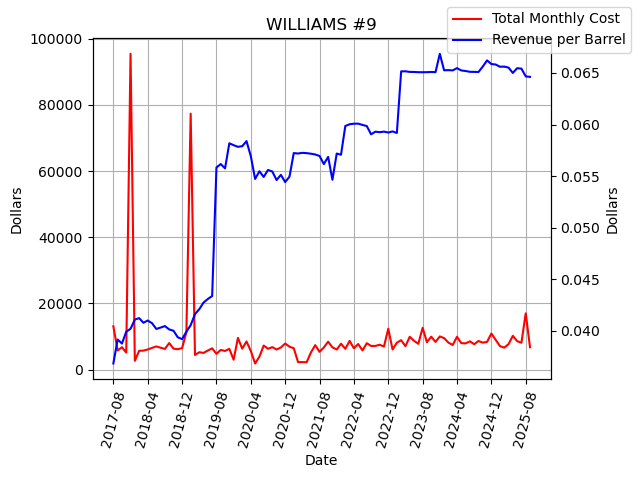

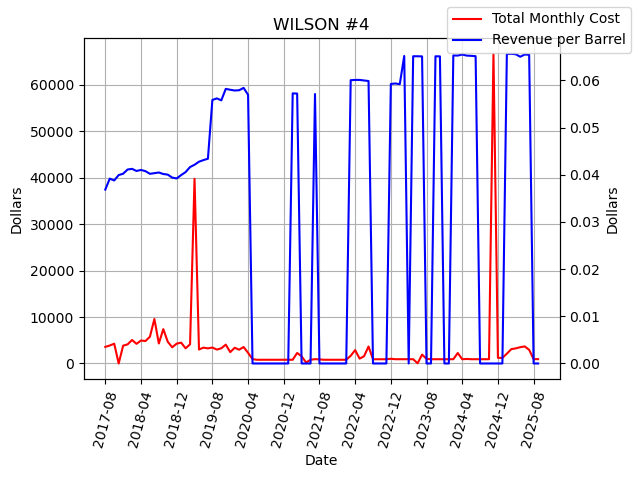

In [6]:
# Total Cost vs Revenue per Barrel
for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    fig, ax1 = plt.subplots()
    ax1.plot(
        filtered_df["Year-Month"], 
        filtered_df["Total Cost"], 
        label="Total Monthly Cost",
        color="red"
    )
    ax2 = ax1.twinx()
    ax2.plot(
        filtered_df["Year-Month"], 
        filtered_df["Revenue per Barrel"], 
        label="Revenue per Barrel",
        color="blue"
    )
    fig.legend()
    ax1.grid()
    ax1.set_title(well)
    ax1.tick_params(axis="x", rotation=75)
    # reduce number of x ticks
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.set_ylabel("Dollars")
    ax1.set_xlabel("Date")
    ax2.set_ylabel("Dollars")
    plt.tight_layout()
    fig.savefig(well + "Total Cost vs Revenue per Barrel.pdf") 

In [46]:
# Electrical Bills vs Cost per Barrel
for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    fig, ax1 = plt.subplots()
    ax1.plot(
        filtered_df["Year-Month"], 
        filtered_df["Electrical Bill"], 
        label="Electrical Cost",
        color="red"
    )
    ax2 = ax1.twinx()
    ax2.plot(
        filtered_df["Year-Month"], 
        filtered_df["Electrical Cost per Barrel"], 
        label="Electrical Cost per Barrel",
        color="blue"
    )
    fig.legend()
    ax1.grid()
    ax1.set_title(well)
    ax1.set_ylim(0, max(main_df["Electrical Bill"]))
    ax1.tick_params(axis="x", rotation=75)
    # reduce number of x ticks
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.set_ylabel("Dollars")
    ax1.set_xlabel("Date")
    ax2.set_ylabel("Dollars")
    plt.tight_layout()
    fig.savefig(well + "_electrical_vs_cost_per_barrel.pdf")    


In [47]:
# Barrels vs Cost per Barrel
for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    fig, ax1 = plt.subplots()
    ax1.plot(
        filtered_df["Year-Month"], 
        filtered_df["Water Total"], 
        label="Barrels Disposed",
        color="blue"
    )
    ax2 = ax1.twinx()
    ax2.plot(
        filtered_df["Year-Month"], 
        filtered_df["Electrical Cost per Barrel"], 
        label="Electrical Cost per Barrel",
        color="red"
    )
    fig.legend()
    ax1.grid()
    ax1.set_title(well)
    ax1.set_ylim(0, max(main_df["Water Total"]))
    ax1.tick_params(axis="x", rotation=75)
    # reduce number of x ticks
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.set_ylabel("Barrels Disposed")
    ax1.set_xlabel("Date")
    ax2.set_ylabel("Cost per Barrel")
    plt.tight_layout()
    fig.savefig(well + "_barrels_disposed_vs_cost_per_barrel.pdf") 

In [48]:
# Revenue per Barrel vs Barrels Disposed
for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    fig, ax1 = plt.subplots()
    ax1.plot(
        filtered_df["Year-Month"], 
        filtered_df["Revenue per Barrel"], 
        label="Revenue per Barrel",
        color="green"
    )
    ax2 = ax1.twinx()
    ax2.plot(
        filtered_df["Year-Month"], 
        filtered_df["Water Total"], 
        label="Barrels Disposed",
        color="blue"
    )
    fig.legend()
    ax1.grid()
    ax1.set_title(well)
    ax1.set_ylim(0, max(main_df["Revenue per Barrel"]))
    ax2.set_ylim(0, max(main_df["Water Total"]))
    ax1.tick_params(axis="x", rotation=75)
    # reduce number of x ticks
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.set_ylabel("Dollars")
    ax1.set_xlabel("Date")
    ax2.set_ylabel("Barrels Disposed")
    plt.tight_layout()
    fig.savefig(well + " Revenue per Barrel vs Water Total.pdf") 

In [17]:
# Income per Barrel vs Barrels Disposed
plt.ioff()
for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    fig, ax1 = plt.subplots()
    ax1.plot(
        filtered_df["Year-Month"], 
        filtered_df["Income per Barrel"], 
        label="Income per Barrel",
        color="green"
    )
    ax2 = ax1.twinx()
    ax2.plot(
        filtered_df["Year-Month"], 
        filtered_df["Water Total"], 
        label="Barrels Disposed",
        color="blue"
    )
    fig.legend()
    ax1.grid()
    ax1.set_title(well)
    ax1.set_ylim(0, max(main_df["Income per Barrel"]))
    ax2.set_ylim(0, max(main_df["Water Total"]))
    ax1.tick_params(axis="x", rotation=75)
    # reduce number of x ticks
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.set_ylabel("Dollars")
    ax1.set_xlabel("Date")
    ax2.set_ylabel("Barrels Disposed")
    plt.tight_layout()
    fig.savefig(well + " Income per Barrel vs Water Total.pdf") 

C:\Users\jroland\AppData\Local\Temp\ipykernel_24216\360235775.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax1 = plt.subplots()


In [25]:
#KWH per Barrel vs Water
plt.ioff()
for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    fig, ax1 = plt.subplots()
    ax1.plot(
        filtered_df["Year-Month"], 
        filtered_df["KWH per Barrel"], 
        label="KWH per Barrel",
        color="red"
    )
    ax2 = ax1.twinx()
    ax2.plot(
        filtered_df["Year-Month"], 
        filtered_df["Water Total"], 
        label="Barrels Disposed",
        color="blue"
    )
    fig.legend()
    ax1.grid()
    ax1.set_title(well)
    ax2.set_ylim(0, max(main_df["Water Total"]))
    ax1.tick_params(axis="x", rotation=75)
    # reduce number of x ticks
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.set_ylabel("KWH per Barrel")
    ax1.set_xlabel("Date")
    ax2.set_ylabel("Barrels Disposed")
    plt.tight_layout()
    fig.savefig(well + " Income per Barrel vs Water Total.pdf") 

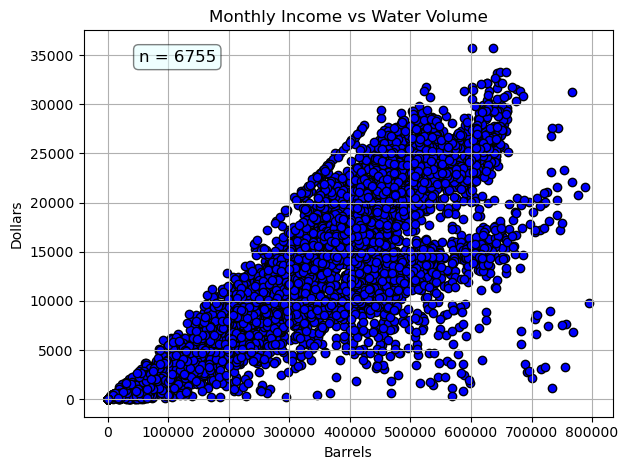

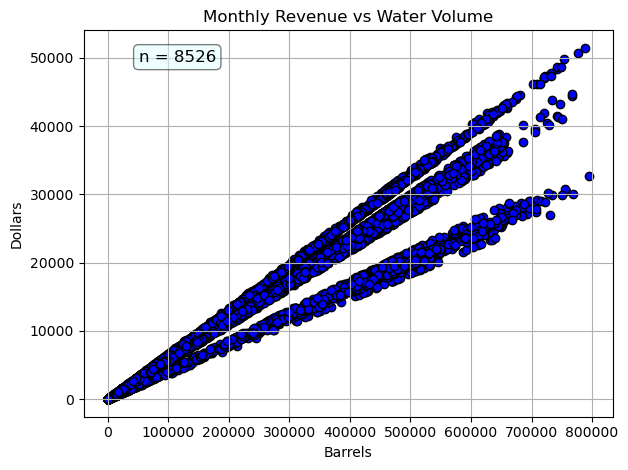

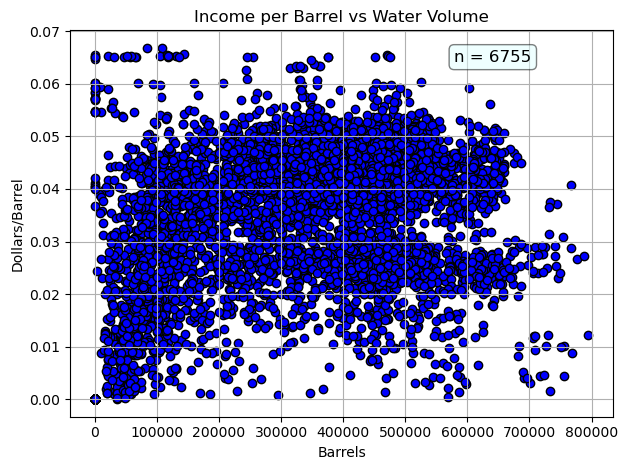

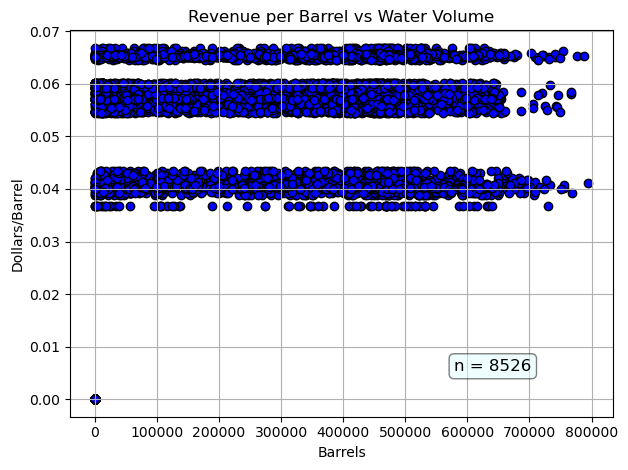

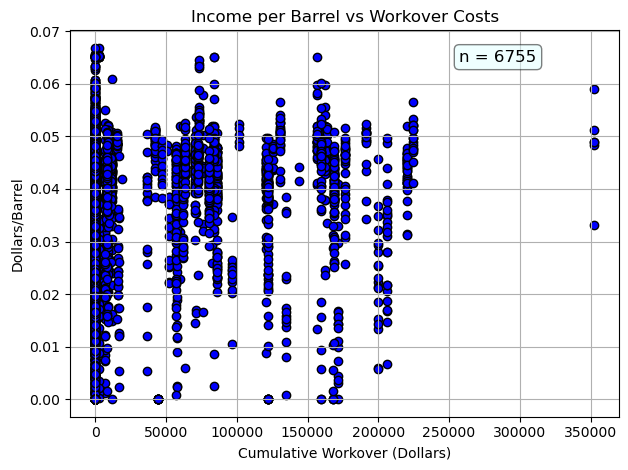

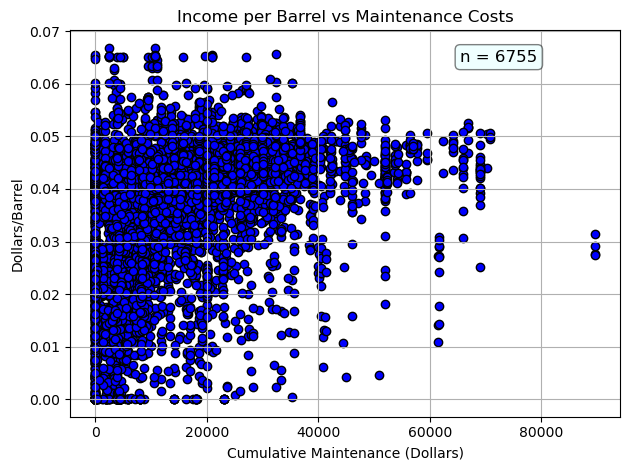

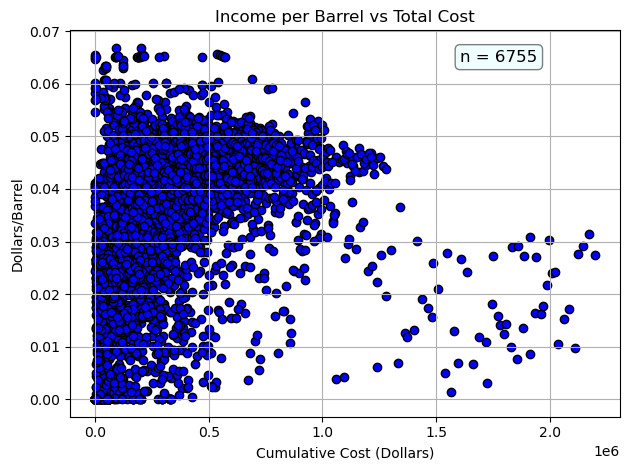

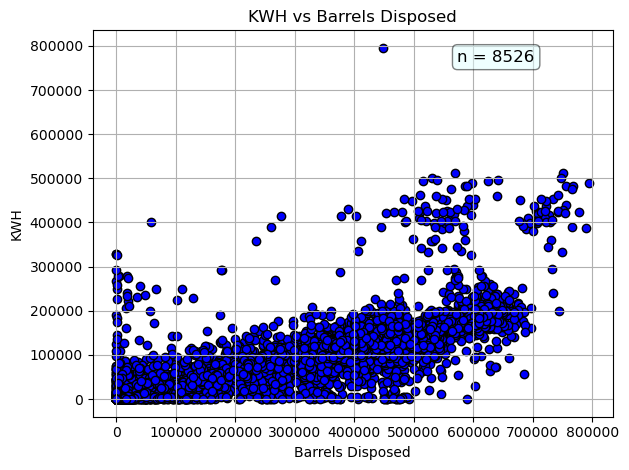

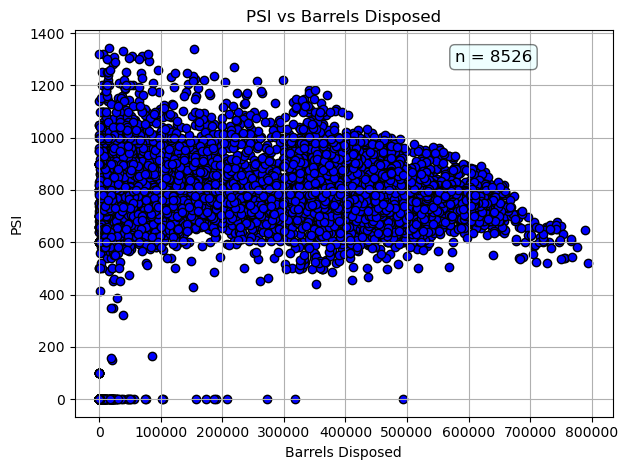

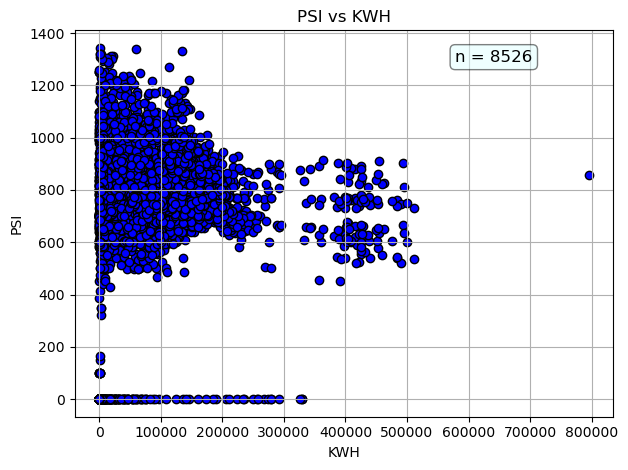

In [32]:
# Some general exploratory scatterplots
# income vs water disposed
plt.ion()
fig, ax = plt.subplots()
# For this plot, we care about the positive relationship between
# income and disposal volume. We don't need negative income values.
filtered_df = main_df[main_df["Income"] >= 0]
ax.scatter(
    filtered_df["Water Total"],
    filtered_df["Income"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Monthly Income vs Water Volume")
ax.set_xlabel("Barrels")
ax.set_ylabel("Dollars")
ax.grid()
text_str = f"n = {len(filtered_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
# transform determines how the coordinates for ax.text() are interpreted
# by default, transform=ax.transData, which plots the text against the literal
# x and y values of the data. transform=ax.transAxes allows for a range of 0 to 1,
# relative to the origin.
ax.text(0.25, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Monthly Income vs Water Volume")

# monthly revenue vs water volume
fig, ax = plt.subplots()
ax.scatter(
    main_df["Water Total"],
    main_df["Revenue"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Monthly Revenue vs Water Volume")
ax.set_xlabel("Barrels")
ax.set_ylabel("Dollars")
ax.grid()
text_str = f"n = {len(main_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.25, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Monthly Revenue vs Water Volume")

# income per barrel vs water disposed
fig, ax = plt.subplots()
ax.scatter(
    filtered_df["Water Total"],
    filtered_df["Income per Barrel"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Income per Barrel vs Water Volume")
ax.set_xlabel("Barrels")
ax.set_ylabel("Dollars/Barrel")
ax.grid()
text_str = f"n = {len(filtered_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Income per Barrel vs Water Volume")

# revenue per barrel vs water disposed
fig, ax = plt.subplots()
ax.scatter(
    main_df["Water Total"],
    main_df["Revenue per Barrel"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Revenue per Barrel vs Water Volume")
ax.set_xlabel("Barrels")
ax.set_ylabel("Dollars/Barrel")
ax.grid()
text_str = f"n = {len(main_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.15, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Revenue per Barrel vs Water Volume")


# income per barrel vs workover cost - need a running total for this to make sense
fig, ax = plt.subplots()
ax.scatter(
    filtered_df["Cumulative Workover Cost"],
    filtered_df["Income per Barrel"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Income per Barrel vs Workover Costs")
ax.set_xlabel("Cumulative Workover (Dollars)")
ax.set_ylabel("Dollars/Barrel")
ax.grid()
text_str = f"n = {len(filtered_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Income per Barrel vs Workover Costs")

# income per barrel vs maintenance cost
fig, ax = plt.subplots()
ax.scatter(
    filtered_df["Cumulative Maintenance Cost"],
    filtered_df["Income per Barrel"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Income per Barrel vs Maintenance Costs")
ax.set_xlabel("Cumulative Maintenance (Dollars)")
ax.set_ylabel("Dollars/Barrel")
ax.grid()
text_str = f"n = {len(filtered_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Income per Barrel vs Maintenance Costs")

# income per barrel vs all cost
fig, ax = plt.subplots()
ax.scatter(
    filtered_df["Cumulative Total Cost"],
    filtered_df["Income per Barrel"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Income per Barrel vs Total Cost")
ax.set_xlabel("Cumulative Cost (Dollars)")
ax.set_ylabel("Dollars/Barrel")
ax.grid()
text_str = f"n = {len(filtered_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Income per Barrel vs Total Costs")

# kwh vs water disposed
fig, ax = plt.subplots()
ax.scatter(
    main_df["Water Total"],
    main_df["Billing KWH"],
    color="blue",
    edgecolor="black"
)
ax.set_title("KWH vs Barrels Disposed")
ax.set_xlabel("Barrels Disposed")
ax.set_ylabel("KWH")
ax.grid()
text_str = f"n = {len(main_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide KWH vs Barrels Disposed")

# kwh vs psi
fig, ax = plt.subplots()
ax.scatter(
    main_df["Water Total"],
    main_df["PSI"],
    color="blue",
    edgecolor="black"
)
ax.set_title("PSI vs Barrels Disposed")
ax.set_xlabel("Barrels Disposed")
ax.set_ylabel("PSI")
ax.grid()
text_str = f"n = {len(main_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide PSI vs Barrels Disposed")

# psi vs kwh
fig, ax = plt.subplots()
ax.scatter(
    main_df["Billing KWH"],
    main_df["PSI"],
    color="blue",
    edgecolor="black"
)
ax.set_title("PSI vs KWH")
ax.set_xlabel("KWH")
ax.set_ylabel("PSI")
ax.grid()
text_str = f"n = {len(main_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide PSI vs KWH")


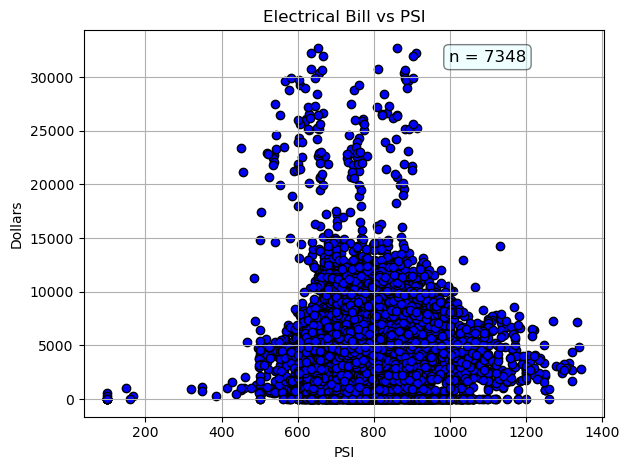

In [8]:
# electrical bill vs psi
filt_df = main_df[~(main_df["PSI"] == 0)]
fig, ax = plt.subplots()
ax.scatter(
    filt_df["PSI"],
    filt_df["Electrical Bill"],
    color="blue",
    edgecolor="black"
)
ax.set_title("Electrical Bill vs PSI")
ax.set_xlabel("PSI")
ax.set_ylabel("Dollars")
ax.grid()
text_str = f"n = {len(filt_df["Name"])}"
props = dict(boxstyle='round', facecolor='lightcyan', alpha=0.5)
ax.text(0.85, 0.95, text_str, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='right', bbox=props)
plt.tight_layout()
fig.savefig("Field-wide Electrical Cost vs PSI")

In [7]:
print(main_df.columns)

Index(['Unnamed: 0', 'Name', 'Year-Month', 'Hours', 'Water Total', 'PSI',
       'Revenue', 'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH',
       'Fuel Rate', 'Electrical Bill', 'Workover Info', 'Workover Cost',
       'Pump Model', 'Pump Number', 'Plunger Size', 'Install Date',
       'Maintenance Cost', 'Maintenance Comments', 'KWH per Barrel',
       'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       '6 Month Avg Water Total', '6 Month Avg KWH', '6 Month Avg Revenue',
       '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Ele

Year-Month
2017-08             NaN
2017-09             NaN
2017-10             NaN
2017-11             NaN
2017-12             NaN
               ...     
2025-05    2.660631e+07
2025-06    2.641028e+07
2025-07    2.638791e+07
2025-08    2.678982e+07
2025-09    2.689105e+07
Name: Water Total, Length: 98, dtype: float64


ValueError: x and y must have same first dimension, but have shapes (98,) and (8526,)

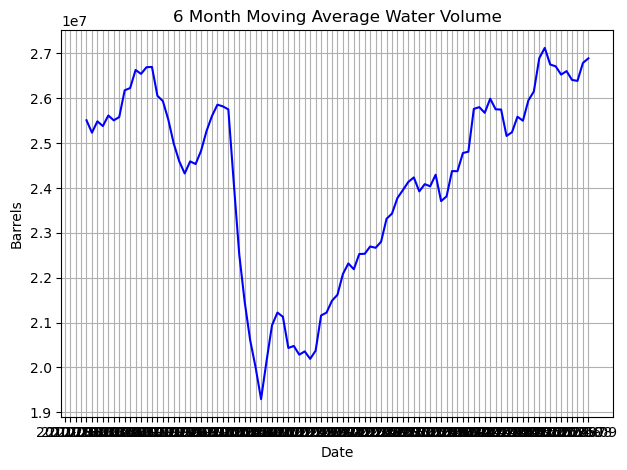

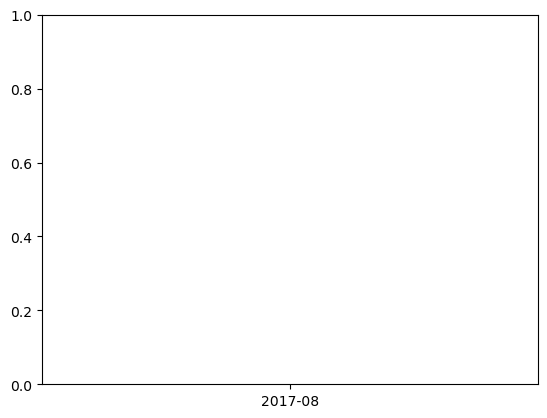

In [24]:
# Exploratory Line plots
monthly_water_total = (
    main_df
    .groupby("Year-Month")["Water Total"]
    .sum()
)

MA_6mo_water_total = (
    monthly_water_total.rolling(window=6)
    .mean()
)

print(MA_6mo_water_total)

monthly_kwh_total = (
    main_df
    .groupby("Year-Month")["Billing KWH"]
    .sum()
)

MA_6mo_kwh_total = (
    monthly_kwh_total.rolling(window=6)
    .mean()
)

monthly_income_total = (
    main_df
    .groupby("Year-Month")["Income"]
    .sum()
)

MA_6mo_income_total = (
    monthly_income_total.rolling(window=6)
    .mean()
)

monthly_revenue_total = (
    main_df
    .groupby("Year-Month")["Revenue"]
    .sum()
)

MA_6mo_revenue_total = (
    monthly_revenue_total.rolling(window=6)
    .mean()
)

monthly_electrical_total = (
    main_df
    .groupby("Year-Month")["Electrical Bill"]
    .sum()
)

MA_6mo_electrical_total = (
    monthly_electrical_total.rolling(window=6)
    .mean()
)

monthly_cost_total = (
    main_df
    .groupby("Year-Month")["Total Cost"]
    .sum()
)

MA_6mo_cost_total = (
    monthly_cost_total.rolling(window=6)
    .mean()
)

monthly_workover_total = (
    main_df
    .groupby("Year-Month")["Workover Cost"]
    .sum()
)

MA_6mo_workover_total = (
    monthly_workover_total.rolling(window=6)
    .mean()
)

monthly_maintenance_total = (
    main_df
    .groupby("Year-Month")["Maintenance Cost"]
    .sum()
)

MA_6mo_maintenance_total = (
    monthly_maintenance_total.rolling(window=6)
    .mean()
)

months = main_df["Year-Month"].unique()

# 6 Month Avg Water Total, 
fig, ax = plt.subplots()
ax.plot(
    months,
    MA_6mo_water_total,
    color="blue"
)
ax.set_title("6 Month Moving Average Water Volume")
ax.set_xlabel("Date")
ax.set_ylabel("Barrels")
ax.grid()
plt.tight_layout()
fig.savefig("Field-wide 6 Month Water Totals")

# '6 Month Avg Income'
fig, ax = plt.subplots()
ax.plot(
    months,
    main_df["6 Month Avg Income"],
    color="blue"
)
ax.set_title("6 Month Moving Average Income")
ax.set_xlabel("Date")
ax.set_ylabel("Dollars")
ax.grid()
plt.tight_layout()
fig.savefig("Field-wide 6 Month Income")

# '6 Month Avg Electrical Cost per Barrel'
fig, ax = plt.subplots()
ax.plot(
    main_df["Year-Month"],
    main_df["6 Month Avg Electrical Cost per Barrel"],
    color="blue"
)
ax.set_title("6 Month Moving Average Electrical Cost")
ax.set_xlabel("Date")
ax.set_ylabel("Dollars")
ax.grid()
plt.tight_layout()
fig.savefig("Field-wide 6 Month Electrical Cost")

# 6 Month average of income vs 6 month average of total cost
fig, ax1 = plt.subplots()
ax1.plot(
    main_df["Year-Month"],
    main_df["6 Month Avg Income"],
    color="blue"
)
ax1.set_title("6 Month Moving Average Income")
ax1.set_xlabel("Date")
ax1.set_ylabel("Dollars")
ax2 = ax1.twinx()
ax2.plot(
    main_df["Year-Month"],
    main_df["6 Month Avg Total Cost"],
    color="red"
)
ax2.set_ylabel("Dollars")
fig.legend()
ax1.grid()
plt.tight_layout()
fig.savefig("Field-wide 6 Month Income vs 6 Month Total Cost")

# 6 Month Avg Total Cost, 6 Month Avg Electrical, 6 Month Avg Maintenance, 6 Month Avg Workover
fig, ax = plt.subplots()
ax.plot(
    main_df["Year-Month"],
    main_df["6 Month Avg Total Cost"],
    color="black"
)
ax.plot(
    main_df["Year-Month"],
    main_df["6 Month Avg Electrical Cost"],
    color="blue"
)
ax.plot(
    main_df["Year-Month"],
    main_df["6 Month Avg Workover Cost"],
    color="red"
)
ax.plot(
    main_df["Year-Month"],
    main_df["6 Month Avg Maintenance Cost"],
    color="grey"
)
ax.set_title("6 Month Moving Average All Costs")
ax.set_xlabel("Date")
ax.set_ylabel("Dollars")
ax.grid()
fig.legend()
plt.tight_layout()
fig.savefig("Field-wide 6 Month Cost Comparisons")

In [32]:
# We want to understand how well workovers are impacting electrical costs. 
# What are some ways to quantify the impact of well workovers?
#      - Average KWH or Average Electrical Cost per Barrel for wells who have had a workover within the test period vs those who have not
#          - ANOVA? 
#                The goal is determine 1) Is there a statistically significant difference and 2) How much of a difference?
#          - predict whether a well is in the group that has had a workover vs one that has not. Probably use logistic regression.
#      
# Ideas:
#      1) Split training and testing data based on well workover dates and run linear regression to predict values after 
#         well workovers. The larger the magnitude of difference between predicted and actual, the *better* the effect of the workover.
#         We are not interested in R_squared for this instance, but the summed magnitude difference between the predicted and actual values.
#         Problem: This will only work for wells where workovers have happened relatively recently.
#         Note:
#      2) Bin wells into two groups: those that have had a workover within the observation period and those that have not. Test to see
#         if there is a difference in means between the groups.